# 04 | Locked Final Expanding-Window Evaluation

## Purpose

This notebook performs the project's final out-of-sample comparison using the model specifications locked in Notebook 03. It does **not** search for new orders, alter the CNY design, or retune a model after observing these results.

The evaluation uses monthly forecast origins from **December 2014 through August 2024**. At every origin, each model is re-estimated using only data available through that month and generates a complete 24-month path. Published month-on-month forecasts are compounded through the reconstructed index and evaluated against published year-on-year inflation.

The comparison has two distinct dimensions:

1. **Reliability:** convergence, warnings, failed origins, and minimum AR and MA root moduli;
2. **Accuracy:** mean error, MAE, and RMSE at horizons 1 through 24 on common successful origins.

> **Locked-evaluation rule:** These results may determine which predeclared model performs best, but they must not be used to redesign the specifications. Any later model revision would constitute a new analysis requiring a new holdout period.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
if not (PROJECT_ROOT / "src").exists():
    raise RuntimeError("Run this notebook from the repository notebooks/ directory.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_ceic import load_cpi_series
from src.data.load_cny_calendar import load_cny_calendar
from src.evaluation.benchmark_validation import (
    run_operational_benchmark_validation,
)
from src.evaluation.internal_validation import (
    ModelSpecification,
    run_expanding_internal_validation,
)
from src.features.cny_regressors import (
    build_cny_regressors,
)
from src.features.reconstruct_index import (
    add_reconstructed_indices,
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "china_cpi.csv"
)

CNY_CALENDAR_PATH = (
    PROJECT_ROOT
    / "data"
    / "external"
    / "chinese_new_year_dates.csv"
)

## 1. Load the full evaluation dataset

The validated CEIC series and reconstructed indices are loaded through the same project functions used in the preceding notebooks. The source file remains licensed and local. The current extract ends in August 2026, which is the last realised target needed for the final August 2024 origin at horizon 24.

In [2]:
cpi = load_cpi_series(DATA_PATH)
cpi = add_reconstructed_indices(cpi)
cpi = cpi.asfreq("MS")

print("Data start:", cpi.index.min())
print("Data end:  ", cpi.index.max())
print("Rows:      ", len(cpi))

Data start: 1985-01-01 00:00:00
Data end:   2026-08-01 00:00:00
Rows:       500


## 2. Lock forecast origins and horizon

An origin dated $T$ uses observations through month $T$ and forecasts months $T+1$ through $T+24$. The first origin is December 2014, immediately after the development sample used in Notebook 03. The final origin is August 2024 because its 24-month target is August 2026, the endpoint of the available data.

There are 117 attempted monthly origins. Model failures are retained in the fitting diagnostics rather than silently replaced or removed.

In [3]:
FINAL_FIRST_ORIGIN = pd.Timestamp("2014-12-01")
FINAL_LAST_ORIGIN = pd.Timestamp("2024-08-01")
FINAL_HORIZON = 24

FINAL_LAST_TARGET = (
    FINAL_LAST_ORIGIN
    + pd.DateOffset(months=FINAL_HORIZON)
)

assert FINAL_LAST_TARGET == pd.Timestamp("2026-08-01")
assert FINAL_LAST_TARGET <= cpi.index.max()

final_origins = pd.date_range(
    FINAL_FIRST_ORIGIN,
    FINAL_LAST_ORIGIN,
    freq="MS",
)

print("First origin:      ", FINAL_FIRST_ORIGIN)
print("Last origin:       ", FINAL_LAST_ORIGIN)
print("Origins attempted: ", len(final_origins))
print("Last target:       ", FINAL_LAST_TARGET)

First origin:       2014-12-01 00:00:00
Last origin:        2024-08-01 00:00:00
Origins attempted:  117
Last target:        2026-08-01 00:00:00


## 3. Prepare headline and core evaluation series

For each target, the evaluation requires three aligned monthly objects:

- published month-on-month inflation for model estimation;
- the reconstructed index for recursive compounding;
- published year-on-year inflation for evaluation.

The sample begins in January 2006, and the assertions require complete monthly values over the evaluation span.

In [4]:
headline_full = (
    cpi.loc["2006-01-01":, "headline_mom_published"]
    .asfreq("MS")
    .astype(float)
)

headline_index_full = (
    cpi.loc[
        headline_full.index,
        "headline_index_reconstructed",
    ]
    .asfreq("MS")
    .astype(float)
)

headline_yoy_full = (
    cpi.loc[
        headline_full.index,
        "headline_yoy_published",
    ]
    .asfreq("MS")
    .astype(float)
)

core_full = (
    cpi.loc["2006-01-01":, "core_mom_published"]
    .asfreq("MS")
    .astype(float)
)

core_index_full = (
    cpi.loc[
        core_full.index,
        "core_index_reconstructed",
    ]
    .asfreq("MS")
    .astype(float)
)

core_yoy_full = (
    cpi.loc[
        core_full.index,
        "core_yoy_published",
    ]
    .asfreq("MS")
    .astype(float)
)

assert headline_full.notna().all()
assert headline_index_full.notna().all()
assert headline_yoy_full.notna().all()

assert core_full.notna().all()
assert core_index_full.notna().all()
assert core_yoy_full.notna().all()

## 4. Build the full CNY calendar regressors

The same predeclared Chinese New Year pressure and post-CNY normalisation rules from Notebook 03 are extended through 2026. Calendar dates are deterministic and observable in advance, so future regressor values are available at each forecast origin without using future CPI outcomes.

In [5]:
cny_calendar = load_cny_calendar(
    CNY_CALENDAR_PATH,
    start_year=2006,
    end_year=2026,
)

cny_result_full = build_cny_regressors(
    cny_calendar=cny_calendar,
    start_date=headline_full.index.min(),
    end_date=headline_full.index.max(),
)

cny_regressors_full = (
    cny_result_full.monthly
    .reindex(headline_full.index)
    .asfreq("MS")
)

assert cny_regressors_full.notna().all().all()

### Matched deterministic design

The CNY-aware headline models use 11 fixed Gregorian month indicators, with January omitted, plus the two CNY regressors. The design is held constant across every origin and forecast horizon. This cell checks complete index alignment through the final August 2026 target.

In [6]:
month_indicators_full = pd.get_dummies(
    headline_full.index.month,
    prefix="month",
    drop_first=True,
    dtype=float,
)

month_indicators_full.index = headline_full.index

headline_exog_full = pd.concat(
    [
        month_indicators_full,
        cny_regressors_full[
            [
                "cny_pressure",
                "cny_normalisation",
            ]
        ],
    ],
    axis=1,
).asfreq("MS")

assert headline_exog_full.index.equals(
    headline_full.index
)

assert headline_exog_full.notna().all().all()

headline_exog_full.tail()

,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,cny_pressure,cny_normalisation
date,,,,,,,,,,,,,
2026-04-01,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-05-01,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-06-01,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-07-01,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-08-01,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Locked headline specifications

The headline comparison contains three statistical models selected before final evaluation:

- **CNY-ignorant SARIMA:** $\mathrm{SARIMA}(1,0,1)(1,0,1)_{12}$ with an intercept;
- **CNY-aware seasonal MA:** fixed month and CNY regressors with $\mathrm{SARIMA}(1,0,1)(0,0,1)_{12}$ errors;
- **CNY-aware seasonal AR robustness:** the same regressors with $\mathrm{SARIMA}(1,0,1)(1,0,0)_{12}$ errors.

The operational benchmark is evaluated separately and added to the paired comparison later.

In [7]:
headline_final_specifications = [
    ModelSpecification(
        label="CNY-ignorant SARIMA",
        order=(1, 0, 1),
        seasonal_order=(1, 0, 1, 12),
        trend="c",
        uses_exog=False,
    ),
    ModelSpecification(
        label="CNY-aware seasonal MA",
        order=(1, 0, 1),
        seasonal_order=(0, 0, 1, 12),
        trend="c",
        uses_exog=True,
    ),
    ModelSpecification(
        label="CNY-aware seasonal AR robustness",
        order=(1, 0, 1),
        seasonal_order=(1, 0, 0, 12),
        trend="c",
        uses_exog=True,
    ),
]

## 6. Locked core specifications

Core inflation is evaluated using the two predeclared statistical candidates:

- **Core ARMA(1,1) seasonal ARMA:** $\mathrm{SARIMA}(1,0,1)(1,0,1)_{12}$;
- **Core MA(2) seasonal ARMA robustness:** $\mathrm{SARIMA}(0,0,2)(1,0,1)_{12}$.

Neither core model includes CNY regressors. The core operational benchmark is added later.

In [8]:
core_final_specifications = [
    ModelSpecification(
        label="Core ARMA(1,1) seasonal ARMA",
        order=(1, 0, 1),
        seasonal_order=(1, 0, 1, 12),
        trend="c",
        uses_exog=False,
    ),
    ModelSpecification(
        label="Core MA(2) seasonal ARMA robustness",
        order=(0, 0, 2),
        seasonal_order=(1, 0, 1, 12),
        trend="c",
        uses_exog=False,
    ),
]

## 7. Evaluate the operational benchmarks

The recursive five-year same-calendar-month benchmark from Notebook 02 is run over all 117 origins for both targets. Each benchmark produces $117\times24=2{,}808$ forecast rows and does not require numerical optimisation, so it supplies a useful reliability reference as well as an accuracy standard.

In [9]:
headline_final_benchmark = (
    run_operational_benchmark_validation(
        monthly_rate=headline_full,
        reconstructed_index=headline_index_full,
        published_yoy=headline_yoy_full,
        model_label="Headline operational benchmark",
        first_origin=FINAL_FIRST_ORIGIN,
        final_origin=FINAL_LAST_ORIGIN,
        horizon=FINAL_HORIZON,
        window_years=5,
    )
)

core_final_benchmark = (
    run_operational_benchmark_validation(
        monthly_rate=core_full,
        reconstructed_index=core_index_full,
        published_yoy=core_yoy_full,
        model_label="Core operational benchmark",
        first_origin=FINAL_FIRST_ORIGIN,
        final_origin=FINAL_LAST_ORIGIN,
        horizon=FINAL_HORIZON,
        window_years=5,
    )
)

print(
    "Headline benchmark rows:",
    len(headline_final_benchmark.forecasts),
)

print(
    "Core benchmark rows:",
    len(core_final_benchmark.forecasts),
)

Headline benchmark rows: 2808
Core benchmark rows: 2808


## 8. Run the headline statistical models

Each locked headline model is re-estimated independently at every origin. A forecast path is accepted only when the fitting and validity rules implemented by the project evaluator are satisfied.

The executed results show an important reliability distinction: both CNY-aware models succeed at all 117 origins, whereas the CNY-ignorant SARIMA succeeds at 104 origins and fails at 13.

In [10]:
headline_final_results = {}

for specification in headline_final_specifications:
    model_exog = (
        headline_exog_full
        if specification.uses_exog
        else None
    )

    result = run_expanding_internal_validation(
        monthly_rate=headline_full,
        reconstructed_index=headline_index_full,
        published_yoy=headline_yoy_full,
        specification=specification,
        first_origin=FINAL_FIRST_ORIGIN,
        final_origin=FINAL_LAST_ORIGIN,
        horizon=FINAL_HORIZON,
        exog=model_exog,
    )

    headline_final_results[
        specification.label
    ] = result

    successful_origins = (
        result.forecasts[
            "forecast_origin"
        ].nunique()
    )

    print(
        specification.label,
        ":",
        successful_origins,
        "successful origins and",
        len(result.forecasts),
        "forecast rows",
    )

CNY-ignorant SARIMA : 104 successful origins and 2496 forecast rows
CNY-aware seasonal MA : 117 successful origins and 2808 forecast rows
CNY-aware seasonal AR robustness : 117 successful origins and 2808 forecast rows


## 9. Run the core statistical models

The same expanding-window procedure is applied to the two locked core models. The executed results show 109 successful origins for the ARMA(1,1) model and 111 for the MA(2) robustness model. Reliability must therefore be reported alongside any common-sample accuracy comparison.

In [11]:
core_final_results = {}

for specification in core_final_specifications:
    result = run_expanding_internal_validation(
        monthly_rate=core_full,
        reconstructed_index=core_index_full,
        published_yoy=core_yoy_full,
        specification=specification,
        first_origin=FINAL_FIRST_ORIGIN,
        final_origin=FINAL_LAST_ORIGIN,
        horizon=FINAL_HORIZON,
        exog=None,
    )

    core_final_results[
        specification.label
    ] = result

    successful_origins = (
        result.forecasts[
            "forecast_origin"
        ].nunique()
    )

    print(
        specification.label,
        ":",
        successful_origins,
        "successful origins and",
        len(result.forecasts),
        "forecast rows",
    )

Core ARMA(1,1) seasonal ARMA : 109 successful origins and 2616 forecast rows
Core MA(2) seasonal ARMA robustness : 111 successful origins and 2664 forecast rows


## 10. Headline fitting reliability

The reliability summary counts attempted, converged, failed, and warning-producing origins and reports the smallest observed AR and MA root modulus.

The two CNY-aware models converge without warnings at all 117 origins. The seasonal-AR robustness model also maintains more comfortable root separation. The CNY-aware seasonal-MA model remains formally invertible but its minimum MA root modulus of approximately 1.001 confirms the near-boundary concern documented during development. The CNY-ignorant model has 13 failed origins, 12 warning origins, and roots extremely close to one.

In [12]:
headline_final_fitting = pd.concat(
    [
        result.fitting
        for result in headline_final_results.values()
    ],
    ignore_index=True,
)

headline_final_reliability = (
    headline_final_fitting.groupby("model")
    .agg(
        attempted_origins=(
            "forecast_origin",
            "count",
        ),
        converged_origins=(
            "converged",
            "sum",
        ),
        failed_origins=(
            "error_message",
            lambda values: values.ne("").sum(),
        ),
        warning_origins=(
            "warning_count",
            lambda values: (values > 0).sum(),
        ),
        minimum_ar_root=(
            "minimum_ar_root_modulus",
            "min",
        ),
        minimum_ma_root=(
            "minimum_ma_root_modulus",
            "min",
        ),
    )
)

headline_final_reliability

,attempted_origins,converged_origins,failed_origins,warning_origins,minimum_ar_root,minimum_ma_root
model,,,,,,
CNY-aware seasonal AR robustness,117,117,0,0,1.088727,1.774007
CNY-aware seasonal MA,117,117,0,0,1.057507,1.001191
CNY-ignorant SARIMA,117,104,13,12,1.000023,1.002655


## 11. Core fitting reliability

Both core models fail at several origins and exhibit minimum root moduli close to one. The MA(2) robustness model succeeds slightly more often, 111 origins versus 109, but neither matches the operational benchmark's numerical reliability. These failures are part of the result, not missing data to be ignored.

In [13]:
core_final_fitting = pd.concat(
    [
        result.fitting
        for result in core_final_results.values()
    ],
    ignore_index=True,
)

core_final_reliability = (
    core_final_fitting.groupby("model")
    .agg(
        attempted_origins=(
            "forecast_origin",
            "count",
        ),
        converged_origins=(
            "converged",
            "sum",
        ),
        failed_origins=(
            "error_message",
            lambda values: values.ne("").sum(),
        ),
        warning_origins=(
            "warning_count",
            lambda values: (values > 0).sum(),
        ),
        minimum_ar_root=(
            "minimum_ar_root_modulus",
            "min",
        ),
        minimum_ma_root=(
            "minimum_ma_root_modulus",
            "min",
        ),
    )
)

core_final_reliability

,attempted_origins,converged_origins,failed_origins,warning_origins,minimum_ar_root,minimum_ma_root
model,,,,,,
"Core ARMA(1,1) seasonal ARMA",117,109,8,8,1.000950,1.010308
Core MA(2) seasonal ARMA robustness,117,111,6,6,1.000605,1.008409


### Failed-origin audit

The detailed tables preserve the forecast origin, training-sample size, convergence flag, warnings, roots when available, and error message for every failed fit. Most failures arise from maximum-likelihood non-convergence; one headline origin records an LU-decomposition error. Keeping the audit visible prevents the common-origin accuracy tables from concealing operational instability.

In [14]:
headline_failed_origins = (
    headline_final_fitting.loc[
        headline_final_fitting[
            "error_message"
        ].ne(""),
        [
            "model",
            "forecast_origin",
            "training_observations",
            "converged",
            "warning_count",
            "warnings",
            "minimum_ar_root_modulus",
            "minimum_ma_root_modulus",
            "error_message",
        ],
    ]
)



core_failed_origins = (
    core_final_fitting.loc[
        core_final_fitting[
            "error_message"
        ].ne(""),
        [
            "model",
            "forecast_origin",
            "training_observations",
            "converged",
            "warning_count",
            "warnings",
            "minimum_ar_root_modulus",
            "minimum_ma_root_modulus",
            "error_message",
        ],
    ]
)
display(headline_failed_origins)
display(core_failed_origins)

,model,forecast_origin,training_observations,converged,warning_count,warnings,minimum_ar_root_modulus,minimum_ma_root_modulus,error_message
4,CNY-ignorant SARIMA,2015-04-01,112,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
14,CNY-ignorant SARIMA,2016-02-01,122,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
16,CNY-ignorant SARIMA,2016-04-01,124,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
32,CNY-ignorant SARIMA,2017-08-01,140,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
42,CNY-ignorant SARIMA,2018-06-01,150,False,0,,NaN,NaN,LinAlgError: LU decomposition error.
55,CNY-ignorant SARIMA,2019-07-01,163,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
58,CNY-ignorant SARIMA,2019-10-01,166,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
87,CNY-ignorant SARIMA,2022-03-01,195,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
99,CNY-ignorant SARIMA,2023-03-01,207,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
101,CNY-ignorant SARIMA,2023-05-01,209,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...


,model,forecast_origin,training_observations,converged,warning_count,warnings,minimum_ar_root_modulus,minimum_ma_root_modulus,error_message
29,"Core ARMA(1,1) seasonal ARMA",2017-05-01,137,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
39,"Core ARMA(1,1) seasonal ARMA",2018-03-01,147,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
50,"Core ARMA(1,1) seasonal ARMA",2019-02-01,158,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
51,"Core ARMA(1,1) seasonal ARMA",2019-03-01,159,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
53,"Core ARMA(1,1) seasonal ARMA",2019-05-01,161,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
62,"Core ARMA(1,1) seasonal ARMA",2020-02-01,170,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
68,"Core ARMA(1,1) seasonal ARMA",2020-08-01,176,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
70,"Core ARMA(1,1) seasonal ARMA",2020-10-01,178,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
155,Core MA(2) seasonal ARMA robustness,2018-02-01,146,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...
159,Core MA(2) seasonal ARMA robustness,2018-06-01,150,False,1,Maximum Likelihood optimization failed to conv...,NaN,NaN,RuntimeError: Maximum-likelihood estimation di...


## 12. Construct the common headline origin set

Accuracy must be compared on identical realised episodes. The common headline set therefore contains only origins at which all three statistical models produced valid 24-month paths. This yields **104 common origins**, spanning December 2014 through August 2024 with gaps at the 13 failed CNY-ignorant origins.

In [15]:
headline_final_forecasts = pd.concat(
    [
        result.forecasts
        for result in headline_final_results.values()
    ],
    ignore_index=True,
)

headline_expected_models = {
    specification.label
    for specification in headline_final_specifications
}

headline_models_by_origin = (
    headline_final_forecasts[
        [
            "forecast_origin",
            "model",
        ]
    ]
    .drop_duplicates()
    .groupby("forecast_origin")["model"]
    .agg(set)
)

headline_common_origins = (
    headline_models_by_origin.loc[
        headline_models_by_origin.apply(
            lambda model_set: (
                model_set == headline_expected_models
            )
        )
    ]
    .index
)

print(
    "Headline common successful origins:",
    len(headline_common_origins),
)

print(
    "Headline first common origin:",
    headline_common_origins.min(),
)

print(
    "Headline last common origin:",
    headline_common_origins.max(),
)

Headline common successful origins: 104
Headline first common origin: 2014-12-01 00:00:00
Headline last common origin: 2024-08-01 00:00:00


### Add the headline benchmark and verify pairing

The benchmark forecasts are restricted to the same 104 common origins and appended to the statistical forecasts. The count table must equal 104 for every model at every horizon. This assertion guarantees a paired comparison rather than allowing a model with fewer difficult origins to receive an easier sample.

In [16]:
headline_final_comparison = pd.concat(
    [
        headline_final_forecasts.loc[
            headline_final_forecasts[
                "forecast_origin"
            ].isin(headline_common_origins)
        ],
        headline_final_benchmark.forecasts.loc[
            headline_final_benchmark.forecasts[
                "forecast_origin"
            ].isin(headline_common_origins)
        ],
    ],
    ignore_index=True,
)

headline_final_counts = (
    headline_final_comparison.groupby(
        [
            "model",
            "horizon",
        ]
    )
    .size()
    .unstack("horizon")
)

assert headline_final_counts.eq(
    len(headline_common_origins)
).all().all()

headline_final_counts

horizon,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
model,,,,,,,,,,,,,,,,,,,,,
CNY-aware seasonal AR robustness,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104
CNY-aware seasonal MA,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104
CNY-ignorant SARIMA,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104
Headline operational benchmark,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104


## 13. Construct the common core origin set

The common core set is the intersection of successful origins for both statistical models. It contains **104 origins**. The coincidence with the headline count does not imply that the excluded calendar months are identical; each target's intersection is constructed independently.

In [17]:
core_final_forecasts = pd.concat(
    [
        result.forecasts
        for result in core_final_results.values()
    ],
    ignore_index=True,
)

core_expected_models = {
    specification.label
    for specification in core_final_specifications
}

core_models_by_origin = (
    core_final_forecasts[
        [
            "forecast_origin",
            "model",
        ]
    ]
    .drop_duplicates()
    .groupby("forecast_origin")["model"]
    .agg(set)
)

core_common_origins = (
    core_models_by_origin.loc[
        core_models_by_origin.apply(
            lambda model_set: (
                model_set == core_expected_models
            )
        )
    ]
    .index
)

print(
    "Core common successful origins:",
    len(core_common_origins),
)

print(
    "Core first common origin:",
    core_common_origins.min(),
)

print(
    "Core last common origin:",
    core_common_origins.max(),
)

Core common successful origins: 104
Core first common origin: 2014-12-01 00:00:00
Core last common origin: 2024-08-01 00:00:00


### Add the core benchmark and verify pairing

The core benchmark is restricted to the same 104 core origins. The count assertion verifies that all three core methods contribute exactly 104 errors at every forecast horizon.

In [18]:
core_final_comparison = pd.concat(
    [
        core_final_forecasts.loc[
            core_final_forecasts[
                "forecast_origin"
            ].isin(core_common_origins)
        ],
        core_final_benchmark.forecasts.loc[
            core_final_benchmark.forecasts[
                "forecast_origin"
            ].isin(core_common_origins)
        ],
    ],
    ignore_index=True,
)

core_final_counts = (
    core_final_comparison.groupby(
        [
            "model",
            "horizon",
        ]
    )
    .size()
    .unstack("horizon")
)

assert core_final_counts.eq(
    len(core_common_origins)
).all().all()

core_final_counts

horizon,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
model,,,,,,,,,,,,,,,,,,,,,
"Core ARMA(1,1) seasonal ARMA",104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104
Core MA(2) seasonal ARMA robustness,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104
Core operational benchmark,104,104,104,104,104,104,104,104,104,104,...,104,104,104,104,104,104,104,104,104,104


## 14. Define final evaluation metrics

Forecast error follows the project convention

$$
e_{T+h\mid T}
=
y_{T+h}-\widehat{y}_{T+h\mid T}.
$$

Thus, a negative mean error indicates that forecasts are too high on average. Horizon-specific metrics are

$$
\mathrm{MAE}_h
=
\frac{1}{N_h}\sum_{i=1}^{N_h}|e_{i,h}|,
$$

and

$$
\mathrm{RMSE}_h
=
\sqrt{\frac{1}{N_h}\sum_{i=1}^{N_h}e_{i,h}^2}.
$$

RMSE penalises large misses more heavily than MAE. Both are reported in percentage points of year-on-year inflation.

In [19]:
def calculate_final_metrics(
    forecasts,
):
    """Calculate horizon-level final evaluation metrics."""
    metrics = (
        forecasts.groupby(
            [
                "model",
                "horizon",
            ],
            as_index=False,
        )
        .agg(
            forecast_count=(
                "forecast_error",
                "count",
            ),
            mean_error=(
                "forecast_error",
                "mean",
            ),
            mae=(
                "absolute_error",
                "mean",
            ),
            mse=(
                "squared_error",
                "mean",
            ),
        )
    )

    metrics["rmse"] = np.sqrt(
        metrics["mse"]
    )

    return metrics.drop(
        columns="mse"
    )

## 15. Calculate headline and core metrics

The full metric objects contain results for every horizon from 1 through 24. Horizons 1, 3, 6, 12, and 24 are displayed as concise reference points without replacing the full horizon profiles used in the plots.

In [20]:
headline_final_metrics = calculate_final_metrics(
    headline_final_comparison
)

core_final_metrics = calculate_final_metrics(
    core_final_comparison
)

FINAL_HIGHLIGHTED_HORIZONS = [
    1,
    3,
    6,
    12,
    24,
]

headline_final_summary = (
    headline_final_metrics.loc[
        headline_final_metrics[
            "horizon"
        ].isin(FINAL_HIGHLIGHTED_HORIZONS)
    ]
    .sort_values(
        [
            "horizon",
            "rmse",
        ]
    )
)

core_final_summary = (
    core_final_metrics.loc[
        core_final_metrics[
            "horizon"
        ].isin(FINAL_HIGHLIGHTED_HORIZONS)
    ]
    .sort_values(
        [
            "horizon",
            "rmse",
        ]
    )
)

display(headline_final_summary)
display(core_final_summary)

,model,horizon,forecast_count,mean_error,mae,rmse
0,CNY-aware seasonal AR robustness,1,104,-0.071548,0.311172,0.381772
48,CNY-ignorant SARIMA,1,104,-0.048885,0.305040,0.402911
72,Headline operational benchmark,1,104,-0.053065,0.305253,0.404776
24,CNY-aware seasonal MA,1,104,-0.094248,0.336384,0.411392
74,Headline operational benchmark,3,104,-0.170359,0.554726,0.712316
50,CNY-ignorant SARIMA,3,104,-0.177564,0.580049,0.746959
2,CNY-aware seasonal AR robustness,3,104,-0.289504,0.618880,0.801181
26,CNY-aware seasonal MA,3,104,-0.366974,0.694129,0.886881
77,Headline operational benchmark,6,104,-0.280660,0.789404,0.995123
53,CNY-ignorant SARIMA,6,104,-0.345760,0.829665,1.061588


,model,horizon,forecast_count,mean_error,mae,rmse
48,Core operational benchmark,1,104,0.014836,0.142735,0.188658
24,Core MA(2) seasonal ARMA robustness,1,104,0.031753,0.147206,0.196861
0,"Core ARMA(1,1) seasonal ARMA",1,104,0.034422,0.148783,0.199098
50,Core operational benchmark,3,104,-0.027588,0.181446,0.228712
2,"Core ARMA(1,1) seasonal ARMA",3,104,0.025881,0.196082,0.247319
26,Core MA(2) seasonal ARMA robustness,3,104,0.017746,0.203070,0.250405
5,"Core ARMA(1,1) seasonal ARMA",6,104,-0.014433,0.262037,0.323937
53,Core operational benchmark,6,104,-0.116075,0.270340,0.338364
29,Core MA(2) seasonal ARMA robustness,6,104,-0.031778,0.283661,0.345254
11,"Core ARMA(1,1) seasonal ARMA",12,104,-0.078346,0.434182,0.552161


### RMSE at selected horizons

The headline result is clear. The operational benchmark has the lowest RMSE at horizons 3, 6, 12, and 24, while the CNY-aware seasonal-AR robustness model is best only at horizon 1. The CNY-aware seasonal-MA model is the weakest headline method at every displayed horizon.

For core inflation, the operational benchmark is best at horizons 1 and 3. The ARMA(1,1) seasonal ARMA model is best at horizons 6, 12, and 24. The MA(2) robustness model does not lead at the displayed horizons.

In [21]:
headline_final_rmse = (
    headline_final_summary.pivot(
        index="horizon",
        columns="model",
        values="rmse",
    )
)

core_final_rmse = (
    core_final_summary.pivot(
        index="horizon",
        columns="model",
        values="rmse",
    )
)

display(headline_final_rmse)
display(core_final_rmse)

model,CNY-aware seasonal AR robustness,CNY-aware seasonal MA,CNY-ignorant SARIMA,Headline operational benchmark
horizon,,,,
1,0.381772,0.411392,0.402911,0.404776
3,0.801181,0.886881,0.746959,0.712316
6,1.274857,1.501731,1.061588,0.995123
12,1.821543,2.171228,1.535541,1.389150
24,1.707569,1.867042,1.604523,1.403294


model,"Core ARMA(1,1) seasonal ARMA",Core MA(2) seasonal ARMA robustness,Core operational benchmark
horizon,,,
1,0.199098,0.196861,0.188658
3,0.247319,0.250405,0.228712
6,0.323937,0.345254,0.338364
12,0.552161,0.611438,0.590578
24,0.617739,0.664361,0.647237


### MAE at selected horizons

Headline MAE reinforces the benchmark result: the operational benchmark is effectively tied with the CNY-ignorant model at horizon 1 and is best from horizon 3 onward. At horizon 24 its MAE is approximately 1.119 percentage points, compared with 1.362 for the CNY-ignorant model and still larger errors for both CNY-aware models.

For core inflation, the benchmark leads at horizons 1 and 3, while the ARMA(1,1) model leads at horizons 6, 12, and 24.

In [22]:
headline_final_mae = (
    headline_final_summary.pivot(
        index="horizon",
        columns="model",
        values="mae",
    )
)

core_final_mae = (
    core_final_summary.pivot(
        index="horizon",
        columns="model",
        values="mae",
    )
)

display(headline_final_mae)
display(core_final_mae)

model,CNY-aware seasonal AR robustness,CNY-aware seasonal MA,CNY-ignorant SARIMA,Headline operational benchmark
horizon,,,,
1,0.311172,0.336384,0.305040,0.305253
3,0.618880,0.694129,0.580049,0.554726
6,1.026007,1.244534,0.829665,0.789404
12,1.570619,1.962627,1.175707,1.110810
24,1.482075,1.671720,1.362262,1.118886


model,"Core ARMA(1,1) seasonal ARMA",Core MA(2) seasonal ARMA robustness,Core operational benchmark
horizon,,,
1,0.148783,0.147206,0.142735
3,0.196082,0.203070,0.181446
6,0.262037,0.283661,0.270340
12,0.434182,0.505136,0.467498
24,0.519290,0.566051,0.546966


### Mean error and forecast bias

All headline methods have negative mean errors, and the negative bias grows with horizon. Because error is actual minus forecast, the models systematically overforecast published headline year-on-year inflation. The CNY-aware models show the largest long-horizon overforecasting, reaching mean errors of about $-1.78$ and $-1.33$ percentage points at horizon 12.

Core biases are much smaller. The statistical models move from slight underforecasting at short horizons to modest overforecasting later. The core benchmark develops a more pronounced negative bias at medium and long horizons.

In [23]:
headline_final_bias = (
    headline_final_summary.pivot(
        index="horizon",
        columns="model",
        values="mean_error",
    )
)

core_final_bias = (
    core_final_summary.pivot(
        index="horizon",
        columns="model",
        values="mean_error",
    )
)

display(headline_final_bias)
display(core_final_bias)



model,CNY-aware seasonal AR robustness,CNY-aware seasonal MA,CNY-ignorant SARIMA,Headline operational benchmark
horizon,,,,
1,-0.071548,-0.094248,-0.048885,-0.053065
3,-0.289504,-0.366974,-0.177564,-0.170359
6,-0.609630,-0.793733,-0.345760,-0.280660
12,-1.325875,-1.776821,-0.757161,-0.503666
24,-1.245474,-1.499536,-1.055647,-0.543900


model,"Core ARMA(1,1) seasonal ARMA",Core MA(2) seasonal ARMA robustness,Core operational benchmark
horizon,,,
1,0.034422,0.031753,0.014836
3,0.025881,0.017746,-0.027588
6,-0.014433,-0.031778,-0.116075
12,-0.078346,-0.111061,-0.258746
24,-0.090902,-0.117116,-0.219718


## 16. Headline RMSE profile across all horizons

The full horizon curve shows that the CNY-aware models' disadvantage widens as monthly forecast errors accumulate through the reconstructed index path. The operational benchmark becomes the strongest general headline forecaster beyond the shortest horizon. This is a forecast-performance result, not evidence that Chinese New Year has no effect on monthly inflation; the corresponding joint inferential question is addressed separately in Notebook 05.

Saved: outputs/figures/04_headline_final_rmse.png


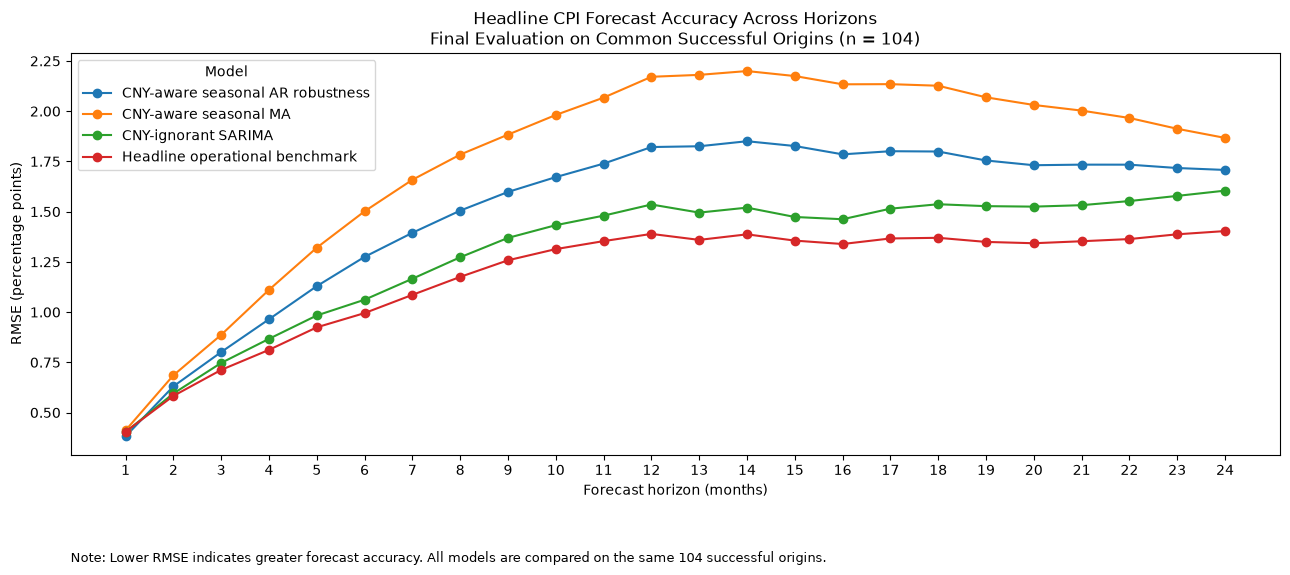

In [24]:
# Plot and save final headline RMSE

OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures"
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

headline_final_rmse_plot = (
    headline_final_metrics.pivot(
        index="horizon",
        columns="model",
        values="rmse",
    )
)

ax = headline_final_rmse_plot.plot(
    marker="o",
    figsize=(13, 6),
)

ax.set_title(
    "Headline CPI Forecast Accuracy Across Horizons\n"
    "Final Evaluation on Common Successful Origins (n = 104)"
)
ax.set_xlabel("Forecast horizon (months)")
ax.set_ylabel("RMSE (percentage points)")
ax.set_xticks(range(1, 25))
ax.legend(
    title="Model",
    loc="upper left",
)

ax.text(
    0.0,
    -0.24,
    (
        "Note: Lower RMSE indicates greater forecast accuracy. "
        "All models are compared on the same 104 successful origins."
    ),
    transform=ax.transAxes,
    fontsize=9,
    ha="left",
    va="top",
)

plt.tight_layout()

headline_figure_path = (
    OUTPUT_FIGURES
    / "04_headline_final_rmse.png"
)

ax.figure.savefig(
    headline_figure_path,
    dpi=300,
    bbox_inches="tight",
)

print("Saved:", headline_figure_path.relative_to(PROJECT_ROOT))
plt.show()


## 17. Core RMSE profile across all horizons

Core inflation is more predictable than headline inflation in absolute error terms. The benchmark is strongest at the shortest horizons, but the ARMA(1,1) seasonal ARMA specification becomes competitive and generally best at medium and longer horizons. The robustness model remains close but does not improve on the primary core model overall.

Saved: outputs/figures/04_core_final_rmse.png


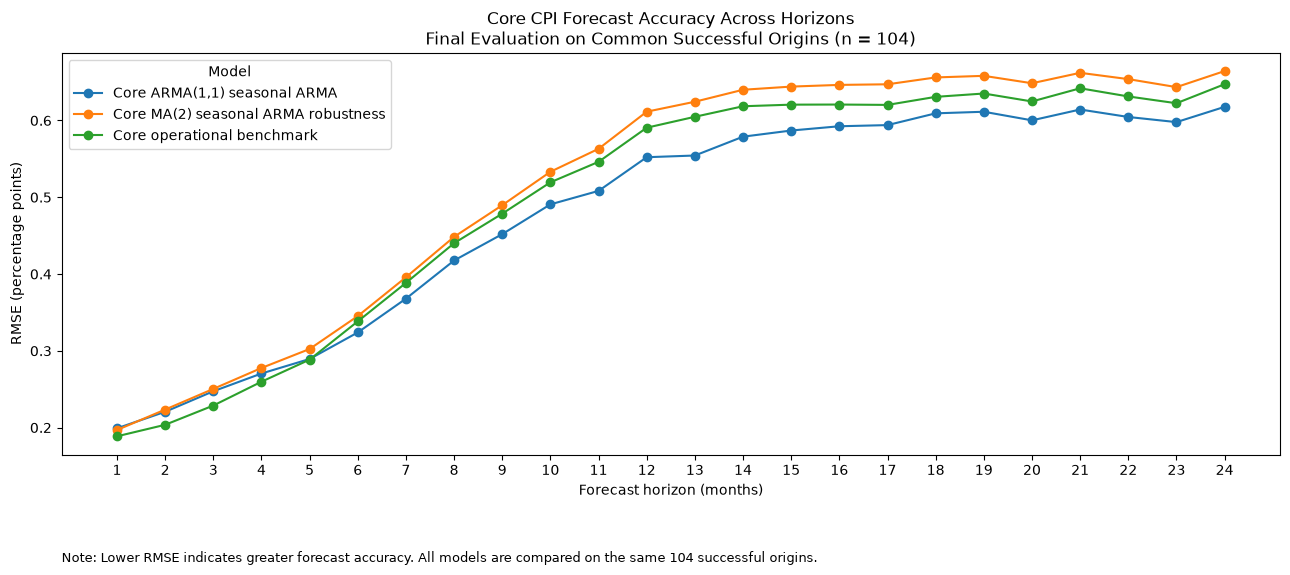

In [ ]:
# Plot and save final core RMSE

OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures"
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

core_final_rmse_plot = (
    core_final_metrics.pivot(
        index="horizon",
        columns="model",
        values="rmse",
    )
)

ax = core_final_rmse_plot.plot(
    marker="o",
    figsize=(13, 6),
)

ax.set_title(
    "Core CPI Forecast Accuracy Across Horizons\n"
    "Final Evaluation on Common Successful Origins (n = 104)"
)
ax.set_xlabel("Forecast horizon (months)")
ax.set_ylabel("RMSE (percentage points)")
ax.set_xticks(range(1, 25))
ax.legend(
    title="Model",
    loc="upper left",
)

ax.text(
    0.0,
    -0.24,
    (
        "Note: Lower RMSE indicates greater forecast accuracy. "
        "All models are compared on the same 104 successful origins."
    ),
    transform=ax.transAxes,
    fontsize=9,
    ha="left",
    va="top",
)

plt.tight_layout()

core_figure_path = (
    OUTPUT_FIGURES
    / "04_core_final_rmse.png"
)

ax.figure.savefig(
    core_figure_path,
    dpi=300,
    bbox_inches="tight",
)

print("Saved:", core_figure_path.relative_to(PROJECT_ROOT))
plt.show()


## 19. Save complete reproducibility outputs

The notebook writes four processed CSV files:

- paired headline forecasts on common origins;
- paired core forecasts on common origins;
- complete headline fitting diagnostics for all attempted origins;
- complete core fitting diagnostics for all attempted origins.

The paired forecast files support the result and inference notebook. The full fitting files preserve failures and warnings that are necessarily absent from the common-origin accuracy sample.

## Final evaluation conclusion

- **Headline:** The simple operational benchmark is the strongest general performer beyond horizon 1 and has perfect operational reliability. The CNY-aware seasonal-AR model provides the best horizon-1 RMSE and complete convergence, but neither CNY-aware model delivers superior medium- or long-horizon year-on-year forecasts. The CNY-aware seasonal-MA model also retains a near-invertible seasonal MA root.
- **Core:** The operational benchmark leads at short horizons, while the locked ARMA(1,1) seasonal ARMA model performs best at the displayed medium and long horizons. Both statistical core models experience some fitting failures.
- **Bias:** Negative mean errors show systematic headline overforecasting, increasingly so at longer horizons. Core bias is smaller.
- **Interpretation:** Better explanatory structure or statistical significance need not imply better multi-step forecast accuracy. Accuracy, reliability, and inference are therefore reported as separate project results.

## 18. Export publication-ready results

The complete forecast and fitting panels remain under `data/processed/` as reproducibility artefacts. This section creates a curated public result package under `outputs/`:

- headline and core RMSE figures across all 24 horizons;
- a final model-reliability summary;
- selected-horizon headline and core metric tables;
- the best model under MAE and RMSE at every horizon;
- a reliability chart showing successful forecast origins out of 117 attempts.

The accuracy tables use the 104 common successful origins for each target. Reliability is reported separately across all 117 attempted origins.

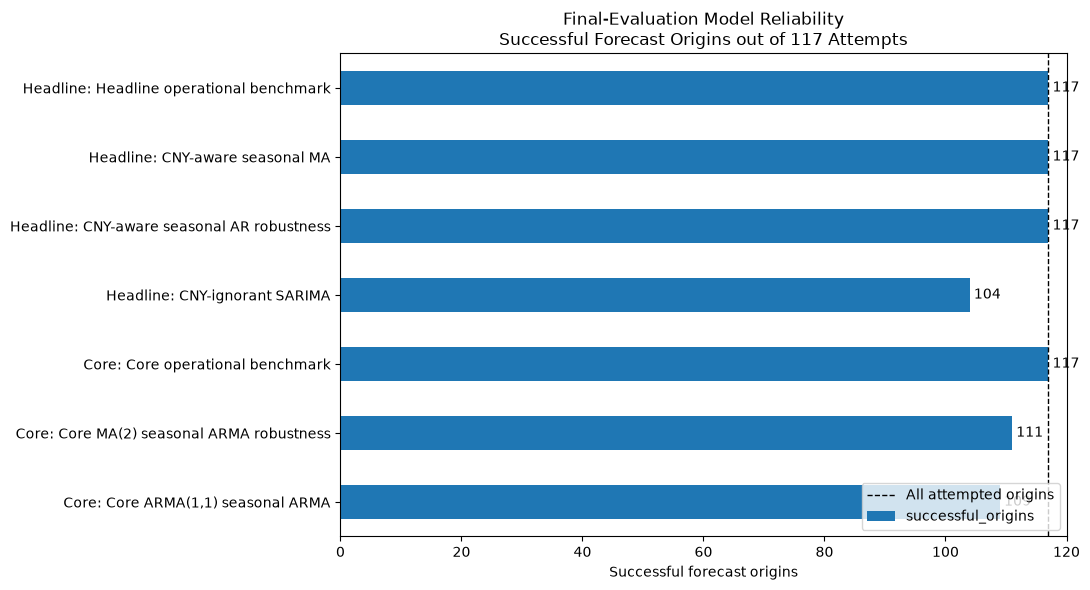

,target,model,attempted_origins,successful_origins,failed_origins,success_rate,converged_origins,warning_origins,minimum_ar_root,minimum_ma_root
0,Core,"Core ARMA(1,1) seasonal ARMA",117,109,8,0.931624,109,8,1.00095,1.010308
1,Core,Core MA(2) seasonal ARMA robustness,117,111,6,0.948718,111,6,1.000605,1.008409
2,Core,Core operational benchmark,117,117,0,1.000000,<NA>,0,<NA>,<NA>
3,Headline,CNY-aware seasonal AR robustness,117,117,0,1.000000,117,0,1.088727,1.774007
4,Headline,CNY-aware seasonal MA,117,117,0,1.000000,117,0,1.057507,1.001191
5,Headline,CNY-ignorant SARIMA,117,104,13,0.888889,104,12,1.000023,1.002655
6,Headline,Headline operational benchmark,117,117,0,1.000000,<NA>,0,<NA>,<NA>


,target,model,horizon,forecast_count,mean_error,mae,rmse
0,Headline,CNY-aware seasonal AR robustness,1,104,-0.071548,0.311172,0.381772
1,Headline,CNY-ignorant SARIMA,1,104,-0.048885,0.305040,0.402911
2,Headline,Headline operational benchmark,1,104,-0.053065,0.305253,0.404776
3,Headline,CNY-aware seasonal MA,1,104,-0.094248,0.336384,0.411392
4,Headline,Headline operational benchmark,3,104,-0.170359,0.554726,0.712316
5,Headline,CNY-ignorant SARIMA,3,104,-0.177564,0.580049,0.746959
6,Headline,CNY-aware seasonal AR robustness,3,104,-0.289504,0.618880,0.801181
7,Headline,CNY-aware seasonal MA,3,104,-0.366974,0.694129,0.886881
8,Headline,Headline operational benchmark,6,104,-0.280660,0.789404,0.995123
9,Headline,CNY-ignorant SARIMA,6,104,-0.345760,0.829665,1.061588


,target,model,horizon,forecast_count,mean_error,mae,rmse
0,Core,Core operational benchmark,1,104,0.014836,0.142735,0.188658
1,Core,Core MA(2) seasonal ARMA robustness,1,104,0.031753,0.147206,0.196861
2,Core,"Core ARMA(1,1) seasonal ARMA",1,104,0.034422,0.148783,0.199098
3,Core,Core operational benchmark,3,104,-0.027588,0.181446,0.228712
4,Core,"Core ARMA(1,1) seasonal ARMA",3,104,0.025881,0.196082,0.247319
5,Core,Core MA(2) seasonal ARMA robustness,3,104,0.017746,0.203070,0.250405
6,Core,"Core ARMA(1,1) seasonal ARMA",6,104,-0.014433,0.262037,0.323937
7,Core,Core operational benchmark,6,104,-0.116075,0.270340,0.338364
8,Core,Core MA(2) seasonal ARMA robustness,6,104,-0.031778,0.283661,0.345254
9,Core,"Core ARMA(1,1) seasonal ARMA",12,104,-0.078346,0.434182,0.552161


,target,loss_function,horizon,best_model,forecast_count,loss_value
0,Core,MAE,1,Core operational benchmark,104,0.142735
1,Core,MAE,2,Core operational benchmark,104,0.159073
2,Core,MAE,3,Core operational benchmark,104,0.181446
3,Core,MAE,4,Core operational benchmark,104,0.209544
4,Core,MAE,5,Core operational benchmark,104,0.236027
...,...,...,...,...,...,...
91,Headline,RMSE,20,Headline operational benchmark,104,1.342733
92,Headline,RMSE,21,Headline operational benchmark,104,1.352658
93,Headline,RMSE,22,Headline operational benchmark,104,1.363561
94,Headline,RMSE,23,Headline operational benchmark,104,1.387238


Saved: outputs/tables/04_final_reliability_summary.csv
Saved: outputs/tables/04_headline_selected_horizon_metrics.csv
Saved: outputs/tables/04_core_selected_horizon_metrics.csv
Saved: outputs/tables/04_best_model_by_horizon.csv
Saved: outputs/figures/04_final_model_reliability.png


In [26]:
# Export publication-ready tables and reliability figure

OUTPUT_TABLES = PROJECT_ROOT / "outputs" / "tables"
OUTPUT_FIGURES = PROJECT_ROOT / "outputs" / "figures"

OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)


def prepare_reliability_table(
    reliability_summary,
    target_name,
):
    """Convert a model-indexed reliability summary to export form."""

    output = reliability_summary.reset_index().copy()
    output.insert(0, "target", target_name)

    output["successful_origins"] = (
        output["attempted_origins"]
        - output["failed_origins"]
    )
    output["success_rate"] = (
        output["successful_origins"]
        / output["attempted_origins"]
    )

    return output


headline_reliability_export = prepare_reliability_table(
    reliability_summary=headline_final_reliability,
    target_name="Headline",
)

core_reliability_export = prepare_reliability_table(
    reliability_summary=core_final_reliability,
    target_name="Core",
)

benchmark_reliability = pd.DataFrame(
    [
        {
            "target": "Headline",
            "model": "Headline operational benchmark",
            "attempted_origins": 117,
            "converged_origins": pd.NA,
            "failed_origins": 0,
            "warning_origins": 0,
            "minimum_ar_root": pd.NA,
            "minimum_ma_root": pd.NA,
            "successful_origins": 117,
            "success_rate": 1.0,
        },
        {
            "target": "Core",
            "model": "Core operational benchmark",
            "attempted_origins": 117,
            "converged_origins": pd.NA,
            "failed_origins": 0,
            "warning_origins": 0,
            "minimum_ar_root": pd.NA,
            "minimum_ma_root": pd.NA,
            "successful_origins": 117,
            "success_rate": 1.0,
        },
    ]
)

final_reliability_summary = pd.concat(
    [
        benchmark_reliability,
        headline_reliability_export,
        core_reliability_export,
    ],
    ignore_index=True,
)

final_reliability_summary = (
    final_reliability_summary[
        [
            "target",
            "model",
            "attempted_origins",
            "successful_origins",
            "failed_origins",
            "success_rate",
            "converged_origins",
            "warning_origins",
            "minimum_ar_root",
            "minimum_ma_root",
        ]
    ]
    .sort_values(
        ["target", "model"],
        ignore_index=True,
    )
)

assert (
    final_reliability_summary["attempted_origins"]
    == (
        final_reliability_summary["successful_origins"]
        + final_reliability_summary["failed_origins"]
    )
).all()
assert final_reliability_summary["attempted_origins"].eq(117).all()
assert final_reliability_summary["success_rate"].between(0, 1).all()

reliability_table_path = (
    OUTPUT_TABLES
    / "04_final_reliability_summary.csv"
)
final_reliability_summary.to_csv(
    reliability_table_path,
    index=False,
    float_format="%.4f",
)


SELECTED_HORIZONS = [1, 3, 6, 12, 24]


def prepare_selected_horizon_metrics(
    metrics,
    target_name,
):
    """Prepare a compact long-format table at selected horizons."""

    selected = metrics.loc[
        metrics["horizon"].isin(SELECTED_HORIZONS)
    ].copy()
    selected.insert(0, "target", target_name)

    return (
        selected[
            [
                "target",
                "model",
                "horizon",
                "forecast_count",
                "mean_error",
                "mae",
                "rmse",
            ]
        ]
        .sort_values(
            ["horizon", "rmse", "model"],
            ignore_index=True,
        )
    )


headline_selected_metrics = prepare_selected_horizon_metrics(
    metrics=headline_final_metrics,
    target_name="Headline",
)
core_selected_metrics = prepare_selected_horizon_metrics(
    metrics=core_final_metrics,
    target_name="Core",
)

assert headline_selected_metrics["forecast_count"].eq(104).all()
assert core_selected_metrics["forecast_count"].eq(104).all()

headline_metrics_path = (
    OUTPUT_TABLES
    / "04_headline_selected_horizon_metrics.csv"
)
core_metrics_path = (
    OUTPUT_TABLES
    / "04_core_selected_horizon_metrics.csv"
)

headline_selected_metrics.to_csv(
    headline_metrics_path,
    index=False,
    float_format="%.4f",
)
core_selected_metrics.to_csv(
    core_metrics_path,
    index=False,
    float_format="%.4f",
)


def identify_best_models(
    metrics,
    target_name,
):
    """Identify the minimum-loss model at each forecast horizon."""

    rmse_winners = (
        metrics.loc[
            metrics.groupby("horizon")["rmse"].idxmin(),
            [
                "horizon",
                "model",
                "forecast_count",
                "rmse",
            ],
        ]
        .rename(
            columns={
                "model": "best_model",
                "rmse": "loss_value",
            }
        )
        .assign(
            target=target_name,
            loss_function="RMSE",
        )
    )

    mae_winners = (
        metrics.loc[
            metrics.groupby("horizon")["mae"].idxmin(),
            [
                "horizon",
                "model",
                "forecast_count",
                "mae",
            ],
        ]
        .rename(
            columns={
                "model": "best_model",
                "mae": "loss_value",
            }
        )
        .assign(
            target=target_name,
            loss_function="MAE",
        )
    )

    return pd.concat(
        [rmse_winners, mae_winners],
        ignore_index=True,
    )


best_model_by_horizon = pd.concat(
    [
        identify_best_models(
            metrics=headline_final_metrics,
            target_name="Headline",
        ),
        identify_best_models(
            metrics=core_final_metrics,
            target_name="Core",
        ),
    ],
    ignore_index=True,
)

best_model_by_horizon = (
    best_model_by_horizon[
        [
            "target",
            "loss_function",
            "horizon",
            "best_model",
            "forecast_count",
            "loss_value",
        ]
    ]
    .sort_values(
        ["target", "loss_function", "horizon"],
        ignore_index=True,
    )
)

assert best_model_by_horizon["forecast_count"].eq(104).all()

winner_path = (
    OUTPUT_TABLES
    / "04_best_model_by_horizon.csv"
)
best_model_by_horizon.to_csv(
    winner_path,
    index=False,
    float_format="%.4f",
)


reliability_plot_data = final_reliability_summary.copy()
reliability_plot_data["display_label"] = (
    reliability_plot_data["target"]
    + ": "
    + reliability_plot_data["model"]
)
reliability_plot_data = reliability_plot_data.sort_values(
    ["target", "successful_origins", "model"]
)

ax = reliability_plot_data.plot(
    x="display_label",
    y="successful_origins",
    kind="barh",
    figsize=(11, 6),
    legend=False,
)
ax.axvline(
    117,
    color="black",
    linestyle="--",
    linewidth=1,
    label="All attempted origins",
)
ax.set_title(
    "Final-Evaluation Model Reliability\n"
    "Successful Forecast Origins out of 117 Attempts"
)
ax.set_xlabel("Successful forecast origins")
ax.set_ylabel("")
ax.set_xlim(0, 120)
ax.legend(loc="lower right")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
    )

plt.tight_layout()

reliability_figure_path = (
    OUTPUT_FIGURES
    / "04_final_model_reliability.png"
)
ax.figure.savefig(
    reliability_figure_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()


display(final_reliability_summary)
display(headline_selected_metrics)
display(core_selected_metrics)
display(best_model_by_horizon)

print("Saved:", reliability_table_path.relative_to(PROJECT_ROOT))
print("Saved:", headline_metrics_path.relative_to(PROJECT_ROOT))
print("Saved:", core_metrics_path.relative_to(PROJECT_ROOT))
print("Saved:", winner_path.relative_to(PROJECT_ROOT))
print("Saved:", reliability_figure_path.relative_to(PROJECT_ROOT))


In [27]:
OUTPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

OUTPUT_PATH.mkdir(
    parents=True,
    exist_ok=True,
)

headline_final_comparison.to_csv(
    OUTPUT_PATH
    / "headline_final_forecasts_common_origins.csv",
    index=False,
)

core_final_comparison.to_csv(
    OUTPUT_PATH
    / "core_final_forecasts_common_origins.csv",
    index=False,
)

headline_final_fitting.to_csv(
    OUTPUT_PATH
    / "headline_final_fitting_diagnostics.csv",
    index=False,
)

core_final_fitting.to_csv(
    OUTPUT_PATH
    / "core_final_fitting_diagnostics.csv",
    index=False,
)